# Hotel Booking Cancellation — Classification (Part A)

**Goal:** predict whether a hotel booking will be canceled (`is_canceled`) using five classification algorithms: Logistic Regression, KNN, Decision Tree, Gaussian Naive Bayes, and SVM. Part B (Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP) is added in Review 2.

## 1. Imports & Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_palette('colorblind')


In [2]:
df = pd.read_csv('../data/hotel_bookings_updated_2024.csv')
df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,city
0,Resort Hotel - Chandigarh,0,342,2024,July,30,27,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2024-07-27 22:16:40.916332324,Chandigarh
1,Resort Hotel - Mumbai,0,737,2024,April,17,28,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2024-04-28 21:56:21.507509066,Mumbai
2,Resort Hotel - Delhi,0,7,2024,September,37,10,0,1,1,...,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2024-09-10 03:46:25.734029096,Delhi
3,Resort Hotel - Kolkata,0,13,2024,August,33,14,0,1,1,...,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2024-08-14 18:07:10.049669568,Kolkata
4,Resort Hotel - Lucknow,0,14,2024,September,37,14,0,2,2,...,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2024-09-14 14:27:32.473846000,Lucknow


## 2. Dataset Audit

In [3]:
print('Rows:', df.shape[0], ' Columns:', df.shape[1])
print('\nDtypes:\n', df.dtypes.value_counts())

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print('\nMissing values:\n', missing)

print('\nDuplicate rows:', df.duplicated().sum())


Rows: 119390  Columns: 33

Dtypes:
 int64      16
str        13
float64     4
Name: count, dtype: int64

Missing values:
 company     112593
agent        16340
country        488
children         4
dtype: int64

Duplicate rows: 0


**Observation:** the dataset has 119,390 bookings and 33 columns. Only `children`, `country`, `agent`, and `company` have missing values — `company` is missing for over 94% of rows, so it isn't usable as a feature. There are a small number of duplicate rows to remove.

## 3. Target Distribution

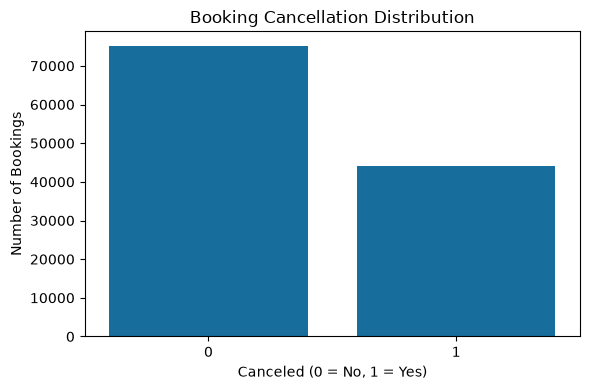

is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='is_canceled')
plt.title('Booking Cancellation Distribution')
plt.xlabel('Canceled (0 = No, 1 = Yes)')
plt.ylabel('Number of Bookings')
plt.tight_layout()
plt.savefig('../models/target_distribution.png', bbox_inches='tight')
plt.show()

print(df['is_canceled'].value_counts(normalize=True).mul(100).round(2))


**Observation:** about 63% of bookings are not canceled and 37% are canceled. The classes are imbalanced but not extremely so — accuracy alone won't tell the full story, which is why precision, recall, weighted F1, and ROC-AUC are all reported below.

## 4. Feature Distributions & Correlation

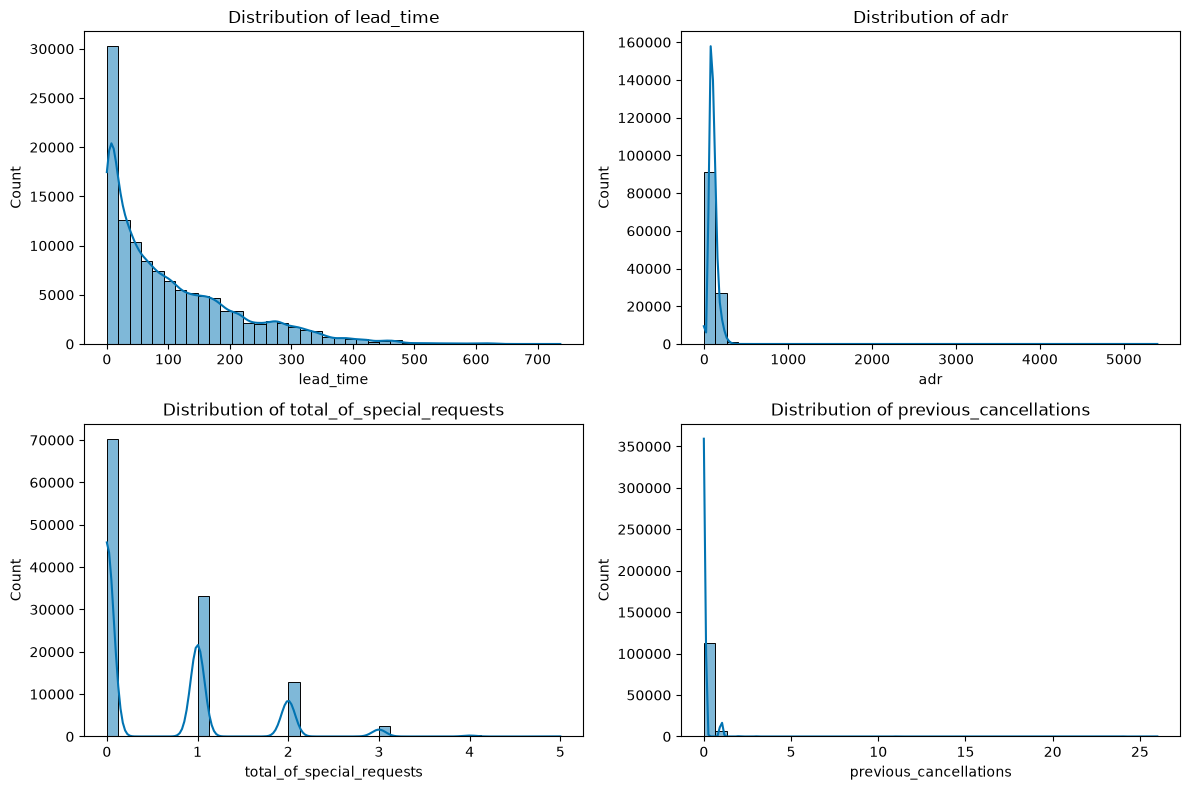

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
num_features_to_plot = ['lead_time', 'adr', 'total_of_special_requests', 'previous_cancellations']
for ax, col in zip(axes.flatten(), num_features_to_plot):
    sns.histplot(df[col], bins=40, ax=ax, kde=True)
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.savefig('../models/eda_feature_distributions.png', bbox_inches='tight')
plt.show()


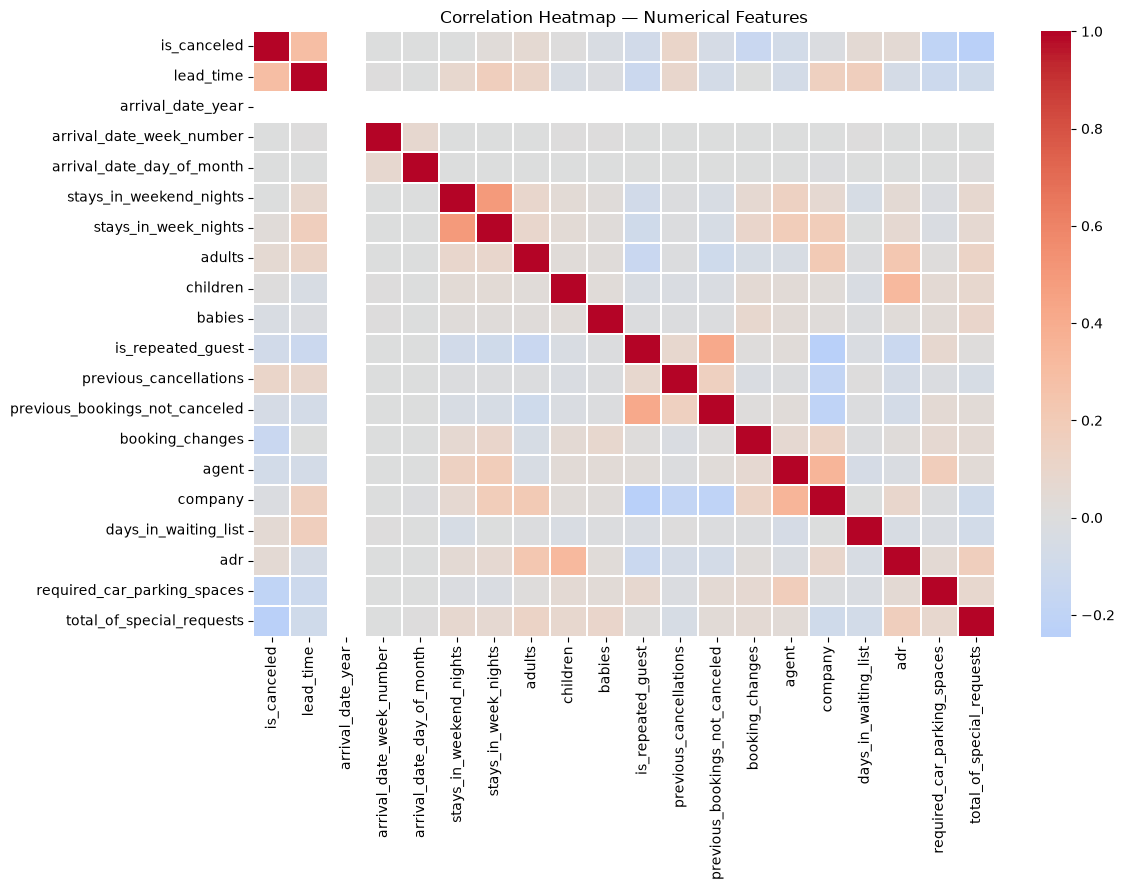

In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(12, 9))
sns.heatmap(df[numeric_cols].corr(), cmap='coolwarm', center=0, annot=False, linewidths=0.3)
plt.title('Correlation Heatmap — Numerical Features')
plt.tight_layout()
plt.savefig('../models/eda_correlation_heatmap.png', bbox_inches='tight')
plt.show()


**Observation:** `lead_time` and `previous_cancellations` show the strongest positive correlation with `is_canceled`, while `total_of_special_requests` is negatively correlated — guests who make special requests are less likely to cancel. Most numeric features are only weakly correlated with each other, so multicollinearity isn't a major concern.

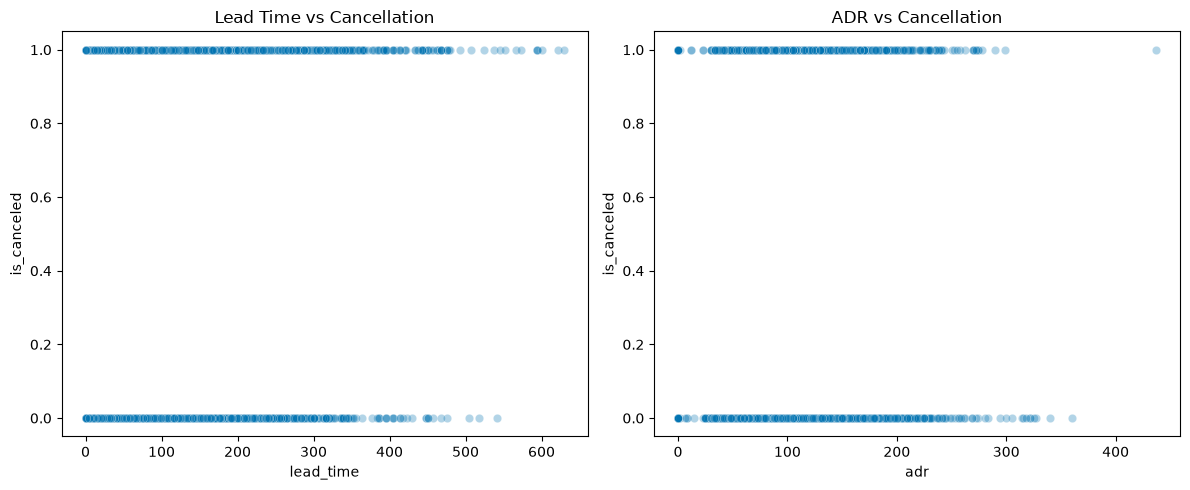

In [7]:
sample = df.sample(4000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=sample, x='lead_time', y='is_canceled', alpha=0.3, ax=axes[0])
axes[0].set_title('Lead Time vs Cancellation')

sns.scatterplot(data=sample, x='adr', y='is_canceled', alpha=0.3, ax=axes[1])
axes[1].set_title('ADR vs Cancellation')

plt.tight_layout()
plt.savefig('../models/eda_scatter_relationships.png', bbox_inches='tight')
plt.show()


**Observation:** cancellations skew toward longer lead times — bookings made far in advance are more likely to fall through. ADR (daily rate) shows a weaker, noisier relationship with cancellation.

## 5. Data Cleaning

**Leakage columns:** `reservation_status` and `reservation_status_date` directly encode the final outcome of the booking — including them would let the model "cheat", so they are dropped.

**Constant column:** `arrival_date_year` has a single value (2024) across all rows, so it carries no information.

**High-cardinality identifier columns:** `agent`, `company`, and `country` are booking-agent and country codes with hundreds/thousands of categories. Keeping them would explode the one-hot feature space and make the model much harder to interpret and defend, and `company` is missing for 94% of rows anyway — so all three are dropped in favor of the other behavioral and booking features.

In [8]:
df['hotel_type'] = df['hotel'].str.extract(r'^(City Hotel|Resort Hotel)')
df = df.drop(columns=['hotel'])

drop_cols = ['reservation_status', 'reservation_status_date', 'arrival_date_year',
             'agent', 'company', 'country']
df = df.drop(columns=drop_cols)

df = df.drop_duplicates().reset_index(drop=True)
df['children'] = df['children'].fillna(0)

print('Shape after cleaning:', df.shape)
print('Remaining missing values:', df.isnull().sum().sum())


Shape after cleaning: (119325, 27)
Remaining missing values: 0


**Outlier treatment:** a handful of bookings have a negative or implausibly high `adr`, or an unrealistic number of adults on one booking — these are data-entry errors rather than genuine extreme cases, so they are removed.

In [9]:
before = len(df)
df = df[(df['adr'] >= 0) & (df['adr'] <= 1000) & (df['adults'] <= 10)].reset_index(drop=True)
print('Rows removed as outliers:', before - len(df))
print('Shape after outlier removal:', df.shape)


Rows removed as outliers: 14
Shape after outlier removal: (119311, 27)


## 6. Feature Engineering

Two engineered features are added:
- `total_nights` = `stays_in_weekend_nights` + `stays_in_week_nights` — the total planned length of stay, which may matter more to cancellation risk than the weekend/weekday split.
- `total_guests` = `adults` + `children` + `babies` — overall party size, a simpler summary than three separate headcount columns.

In [10]:
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df[['total_nights', 'total_guests']].describe()


,total_nights,total_guests
count,119311.000000,119311.000000
mean,3.428167,1.965519
std,2.557799,0.653316
min,0.000000,0.000000
25%,2.000000,2.000000
50%,3.000000,2.000000
75%,4.000000,2.000000
max,69.000000,12.000000


## 7. Target/Feature Split, Stratified Train-Test Split

In [11]:
X = df.drop(columns=['is_canceled'])
y = df['is_canceled']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train target %:', y_train.value_counts(normalize=True).round(3).to_dict())
print('Test target %: ', y_test.value_counts(normalize=True).round(3).to_dict())


Train: (95448, 28)  Test: (23863, 28)
Train target %: {0: 0.63, 1: 0.37}
Test target %:  {0: 0.63, 1: 0.37}


## 8. Preprocessing Pipeline

Numeric features are median-imputed then standardized; categorical features are imputed with an `'Unknown'` placeholder then one-hot encoded. The pipeline is **fit only on the training set** and then applied to the test set, to avoid data leakage.

In [12]:
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'string']).columns.tolist()
print('Numeric features:', len(num_cols))
print('Categorical features:', len(cat_cols), cat_cols)

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='Unknown')),
        ('encode', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print('Processed train shape:', X_train_p.shape)
print('Processed test shape: ', X_test_p.shape)


Numeric features: 18
Categorical features: 10 ['arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'city', 'hotel_type']
Processed train shape: (95448, 94)
Processed test shape:  (23863, 94)


## 9. Model Training & Evaluation

All five models are evaluated with the same helper function on the same test set, so the comparison is fair. KNN and SVM are trained on a stratified 8,000-row subsample of the training set — both are computationally expensive on 95k+ rows, and a subsample keeps training fast without changing what's being compared (all models are still tested on the full held-out test set).

In [13]:
results = {}

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_te)[:, 1]
    else:
        y_score = model.decision_function(X_te)

    results[name] = {
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred),
        'Recall': recall_score(y_te, y_pred),
        'Weighted F1': f1_score(y_te, y_pred, average='weighted'),
        'ROC-AUC': roc_auc_score(y_te, y_score)
    }

    cm = confusion_matrix(y_te, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Not Canceled', 'Canceled'])
    fig, ax = plt.subplots(figsize=(5, 4))
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f'{name} — Confusion Matrix')
    plt.tight_layout()
    safe_name = name.lower().replace(' ', '_')
    plt.savefig(f'../models/confusion_matrix_{safe_name}.png', bbox_inches='tight')
    plt.show()

    print(name, '->', {k: round(v, 4) for k, v in results[name].items()})
    return model


In [14]:
# Stratified subsample for the distance/margin-based models (KNN, SVM)
X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train_p, y_train, train_size=8000, stratify=y_train, random_state=RANDOM_STATE
)


### 9.1 Logistic Regression

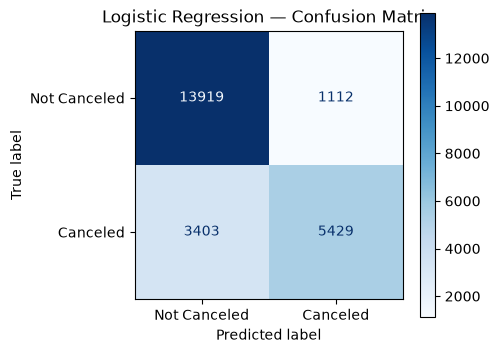

Logistic Regression -> {'Accuracy': 0.8108, 'Precision': 0.83, 'Recall': 0.6147, 'Weighted F1': 0.8034, 'ROC-AUC': 0.8615}


In [15]:
_ = evaluate_model('Logistic Regression',
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    X_train_p, y_train, X_test_p, y_test)


### 9.2 K-Nearest Neighbors

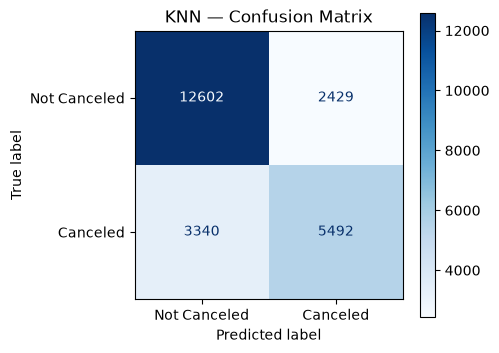

KNN -> {'Accuracy': 0.7582, 'Precision': 0.6933, 'Recall': 0.6218, 'Weighted F1': 0.7552, 'ROC-AUC': 0.8056}


In [16]:
_ = evaluate_model('KNN',
    KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    X_train_sub, y_train_sub, X_test_p, y_test)


### 9.3 Decision Tree

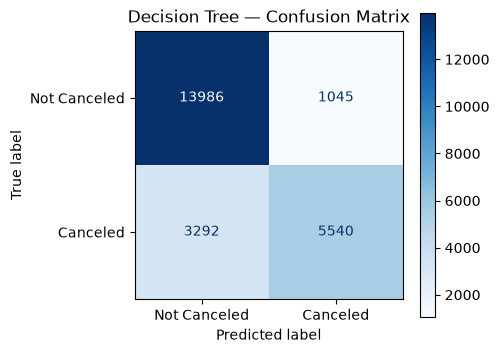

Decision Tree -> {'Accuracy': 0.8183, 'Precision': 0.8413, 'Recall': 0.6273, 'Weighted F1': 0.8113, 'ROC-AUC': 0.8804}


In [17]:
_ = evaluate_model('Decision Tree',
    DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    X_train_p, y_train, X_test_p, y_test)


### 9.4 Gaussian Naive Bayes
GaussianNB requires a dense array, so the sparse one-hot matrix is densified here only.

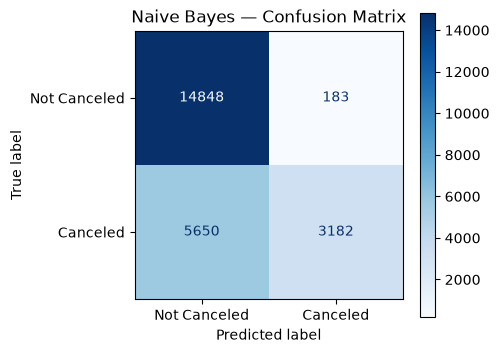

Naive Bayes -> {'Accuracy': 0.7556, 'Precision': 0.9456, 'Recall': 0.3603, 'Weighted F1': 0.7196, 'ROC-AUC': 0.7812}


In [18]:
_ = evaluate_model('Naive Bayes',
    GaussianNB(),
    X_train_p.toarray(), y_train, X_test_p.toarray(), y_test)


### 9.5 Support Vector Machine

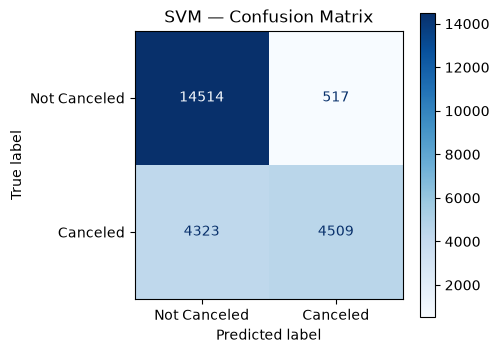

SVM -> {'Accuracy': 0.7972, 'Precision': 0.8971, 'Recall': 0.5105, 'Weighted F1': 0.7807, 'ROC-AUC': 0.8556}


In [19]:
_ = evaluate_model('SVM',
    SVC(kernel='linear', random_state=RANDOM_STATE, cache_size=1000),
    X_train_sub, y_train_sub, X_test_p, y_test)


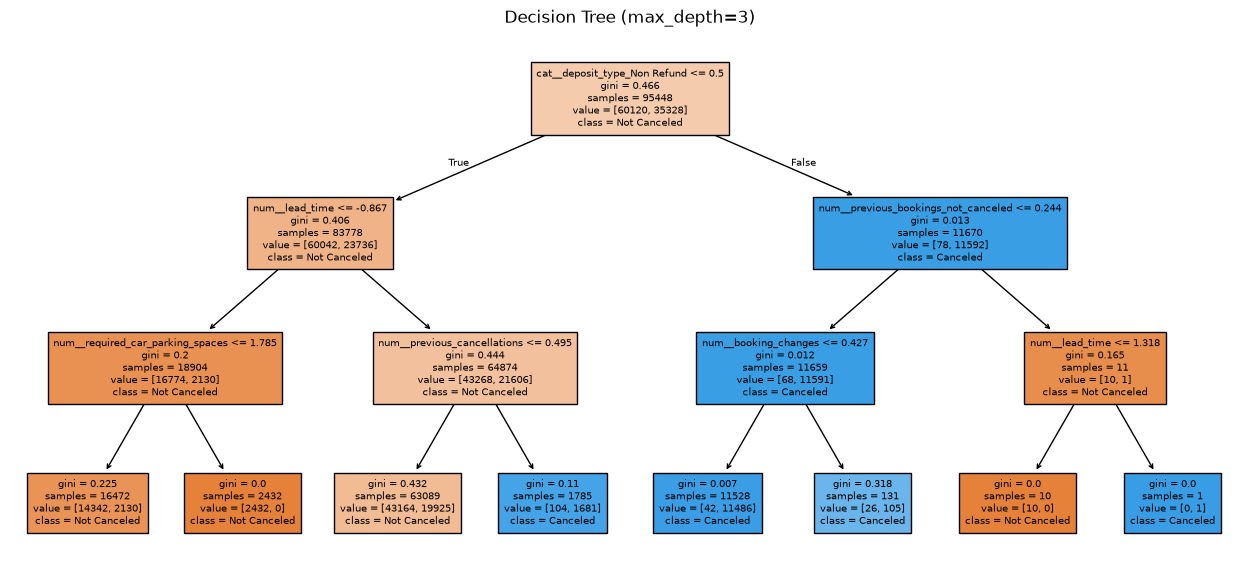

In [37]:
from sklearn.tree import plot_tree
dt_small = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train_p, y_train)
plt.figure(figsize=(16, 7))
plot_tree(dt_small, feature_names=preprocessor.get_feature_names_out(), class_names=['Not Canceled', 'Canceled'], filled=True, fontsize=7)
plt.title('Decision Tree (max_depth=3)')
plt.savefig('../models/decision_tree.png', bbox_inches='tight')
plt.show()

**Observation:** This is a depth-3 tree drawn for illustration. The model evaluated earlier used `max_depth=10`. The tree's first split is on `deposit_type_Non Refund`. Of the 11,670 bookings with a non-refundable deposit, 11,592 (about 99%) were cancelled, so the tree labels that whole branch as Canceled. This is the opposite of what you would expect (a non-refundable booking should be harder to cancel), so it probably reflects how this dataset records such bookings rather than guest behaviour. It also explains why deposit type ranked so high in the Random Forest feature importance.

The other branches use more intuitive features. Among bookings without a non-refundable deposit, a very short lead time (well below average, since the values are standardised) leads to mostly not-cancelled bookings (16,774 of 18,904, about 89%). Within the group of 1,785 bookings with at least one previous cancellation, about 94% were cancelled. All 2,432 bookings that required a parking space were not cancelled. These patterns agree with the EDA and the feature importance, where lead time and previous cancellations stood out.

Some leaves contain very few bookings (for example 11 and 1), so those rules should not be trusted. A tree this small is easy to explain but less accurate than the ensembles, which is the trade-off between interpretability and performance.

In [38]:
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_p, y_train)
coefs = pd.Series(lr.coef_[0], index=preprocessor.get_feature_names_out()).sort_values()
pd.concat([coefs.head(8), coefs.tail(8)]).round(3)

num__required_car_parking_spaces   -2.451
cat__deposit_type_Refundable       -1.842
cat__deposit_type_No Deposit       -1.825
cat__assigned_room_type_I          -1.722
cat__reserved_room_type_A          -1.645
cat__assigned_room_type_G          -1.615
cat__distribution_channel_GDS      -0.878
cat__reserved_room_type_B          -0.868
cat__meal_FB                        0.621
cat__reserved_room_type_P           0.799
cat__assigned_room_type_P           0.799
cat__assigned_room_type_B           1.185
cat__reserved_room_type_G           1.412
cat__assigned_room_type_A           1.904
num__previous_cancellations         2.376
cat__deposit_type_Non Refund        3.495
dtype: float64

**Interpretation of coefficients:** In Logistic Regression a positive coefficient raises the log-odds of cancellation and a negative one lowers it. Taking e to the power of a coefficient gives the odds ratio. The numeric features were standardised, so their coefficients are per one standard deviation, while the one-hot columns compare a category against not being in it.

- **Strongest increase in cancellation:** `deposit_type_Non Refund` (+3.50, odds about 33 times higher) and `previous_cancellations` (+2.38, odds about 11 times higher per standard deviation). A guest who has cancelled before is more likely to cancel again, which matches the EDA. The non-refundable result is the same unexpected pattern the decision tree showed, so it probably reflects how this dataset records those bookings.
- **Strongest decrease:** `required_car_parking_spaces` (-2.45, odds about 0.09 times), `deposit_type_Refundable` and `No Deposit` (about -1.8 each). Guests who need parking have made practical plans for the stay, so they cancel much less.
- **Room types:** the `reserved_room_type` and `assigned_room_type` columns have large coefficients of opposite sign (for example reserved A -1.65 and assigned A +1.90). These two features are almost the same for most bookings, so their effects offset each other, and single room-type coefficients should not be read on their own.

`lead_time` is not among the largest coefficients here, although it was the top feature in the Random Forest. Logistic Regression can only model a straight-line effect, while the forest can use lead time in non-linear ways and in combination with other features. These coefficients describe associations in the data and are not causes. This is the advantage of Logistic Regression: its model can be read directly, but it scores lower than the ensembles (ROC-AUC 0.862 against 0.912).

## 10. Part A — Comparison Table

In [20]:
comparison_df = pd.DataFrame(results).T.sort_values('ROC-AUC', ascending=False)
comparison_df.round(4)


,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
Decision Tree,0.8183,0.8413,0.6273,0.8113,0.8804
Logistic Regression,0.8108,0.8300,0.6147,0.8034,0.8615
SVM,0.7972,0.8971,0.5105,0.7807,0.8556
KNN,0.7582,0.6933,0.6218,0.7552,0.8056
Naive Bayes,0.7556,0.9456,0.3603,0.7196,0.7812



**Observation:** Decision Tree and Logistic Regression lead on ROC-AUC and weighted F1, with SVM close behind on precision. Naive Bayes trails the others — its assumption that features are conditionally independent given the class doesn't hold well here, since many of the numeric features (e.g. `total_nights` and the two stay-length columns it was built from) are correlated. KNN is held back somewhat by being trained on a smaller subsample. Part B's ensemble methods (Random Forest, Gradient Boosting, AdaBoost, Bagging) are expected to improve on these baselines in Review 2.

PART B

# Part B — Ensemble & Neural Network Classifiers (Review 2)

Part B uses **the same dataset, the same stratified 80:20 split (`random_state=42`) and the same fitted preprocessor** as Part A, so all 10 algorithms can be compared fairly. Algorithms: Random Forest, AdaBoost, Gradient Boosting, Bagging (Decision Tree base), MLP.

In [21]:
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, BaggingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
import joblib

fitted = {}   # keeps the fitted Part B models so we can inspect / save them later

## Random Forest

A single Decision Tree is trained on all the data and can keep splitting until it memorises
the training set, so it has high variance and tends to overfit. A Random Forest trains many
trees instead. Each tree sees a different bootstrap sample of the rows (drawn with
replacement), and at every split it only considers a random subset of the features. For
classification, the trees vote and the majority class wins.

This generalises better because each tree overfits in its own random way, and averaging many
of them cancels out much of that noise. That reduces variance while bias stays about the same.
The random feature subsets keep the trees from being near copies of each other, and averaging
less-correlated trees reduces variance more than averaging similar ones. This is also what
separates a Random Forest from plain Bagging, which uses the same bootstrap idea but lets every
tree see all the features.

`n_estimators=200` is a starting value, not a tuned one. More trees keep lowering variance,
but the gains shrink after a point while training time keeps growing, so 200 is a reasonable
middle ground. Section 17 searches `n_estimators` over [100, 200] with GridSearchCV to check
whether it matters here.

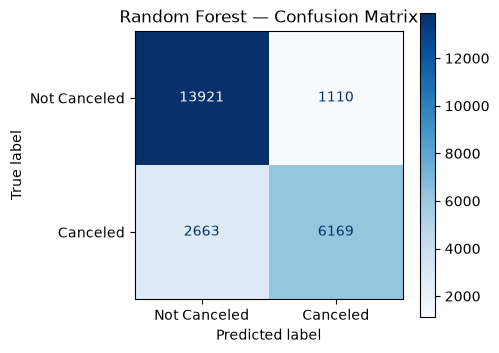

Random Forest -> {'Accuracy': 0.8419, 'Precision': 0.8475, 'Recall': 0.6985, 'Weighted F1': 0.8382, 'ROC-AUC': 0.912}


In [22]:
fitted['Random Forest'] = evaluate_model('Random Forest',
    RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    X_train_p, y_train, X_test_p, y_test)

**Observation:** The Random Forest reaches an accuracy of 0.842, weighted F1 of 0.838 and
ROC-AUC of 0.912. This is a clear improvement on the best Part A model (the Decision Tree,
ROC-AUC about 0.88), which supports the idea that averaging many trees reduces the variance
of a single deep tree.

The confusion matrix shows where the errors are. Of the 15,031 bookings that were not
cancelled, 13,921 were classified correctly and only 1,110 (about 7%) were wrongly flagged
as cancellations. Of the 8,832 bookings that were actually cancelled, 6,169 were caught and
2,663 (about 30%) were missed. This matches the precision/recall gap: precision is 0.848,
so about 85% of the bookings the model flags as cancellations really are cancelled, but
recall is 0.699, so it only finds about 70% of the real cancellations.

So the model is cautious: it is reliable when it predicts a cancellation, but it lets
roughly three in ten cancellations through. For a hotel, a missed cancellation means an
empty room that could have been resold, which is usually costlier than a false alarm, so
recall deserves attention alongside accuracy. Recall could probably be raised, at the cost of
more false alarms, by lowering the decision threshold below 0.5 or by tuning the forest
(section 17).

In [ ]:
Random Forest and its feature-importance plot

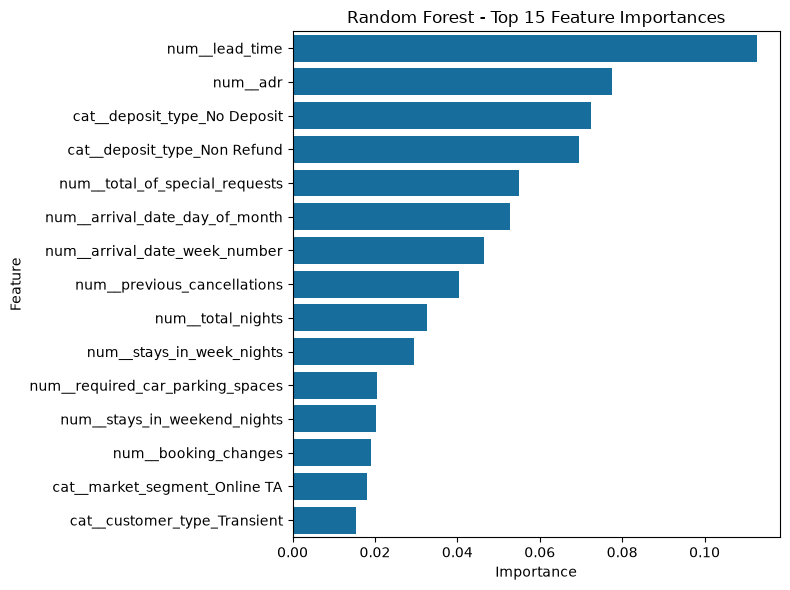

In [23]:
feature_names = preprocessor.get_feature_names_out()
importances = (pd.Series(fitted['Random Forest'].feature_importances_, index=feature_names)
                 .sort_values(ascending=False).head(15))

plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index)
plt.title('Random Forest - Top 15 Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('../models/rf_feature_importance.png', bbox_inches='tight')
plt.show()

**Observation:** `lead_time` is the most important feature (about 0.11), followed by `adr`, the
deposit-type columns, `total_of_special_requests` and `previous_cancellations`. This agrees
with the EDA, where lead time, previous cancellations and special requests stood out.
`deposit_type` appears twice because of one-hot encoding, and its two columns together
carry about 0.14, more than `lead_time` alone. The engineered feature `total_nights` ranks
above its two components, which supports creating it. The high rank of arrival day and week
may partly be an artefact, since impurity-based importance favours features with many
distinct values. These scores show what the forest used to split, not what causes
cancellations. The top features are still plausible: early bookings and bookings without a
deposit are easier to cancel.

# AdaBoost, Gradient Boosting, Bagging, MLP

## AdaBoost

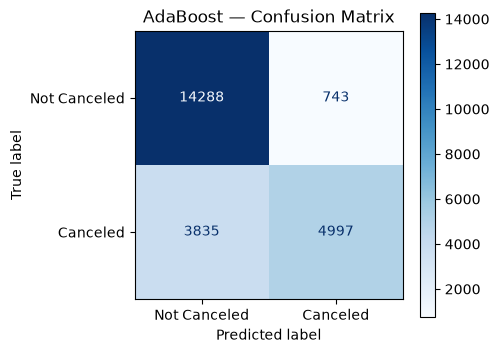

AdaBoost -> {'Accuracy': 0.8082, 'Precision': 0.8706, 'Recall': 0.5658, 'Weighted F1': 0.7967, 'ROC-AUC': 0.8555}


In [24]:
fitted['AdaBoost'] = evaluate_model('AdaBoost',
    AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE),
    X_train_p, y_train, X_test_p, y_test)

**Observation:** AdaBoost reaches an accuracy of 0.808 and ROC-AUC of 0.856, below the Decision Tree (0.880) and Random Forest (0.912), so boosting did not help here. Precision is high (0.871), with only 743 non-cancelled bookings wrongly flagged, but recall is low (0.566): 3,835 of the 8,832 real cancellations were missed. This is probably because its default weak learners are one-split stumps, which can't capture interactions between features like lead time and deposit type. The low recall is its main weakness, since a missed cancellation costs the hotel an empty room.

## Gradient Boosting

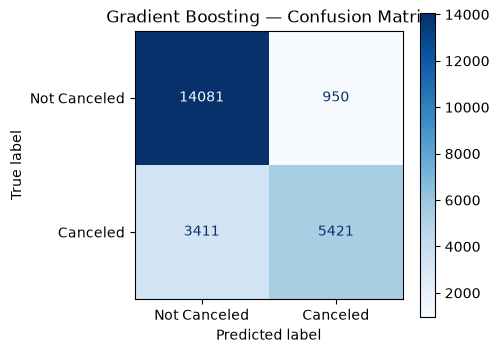

Gradient Boosting -> {'Accuracy': 0.8172, 'Precision': 0.8509, 'Recall': 0.6138, 'Weighted F1': 0.8094, 'ROC-AUC': 0.8862}


In [25]:
fitted['Gradient Boosting'] = evaluate_model('Gradient Boosting',
    GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE),
    X_train_p, y_train, X_test_p, y_test)

**Observation:** Gradient Boosting reaches an accuracy of 0.817 and ROC-AUC of 0.886. That is slightly above the Decision Tree (0.880) but clearly below Random Forest (0.912), so with default settings boosting only gave a small gain. Precision is good (0.851), with 950 non-cancelled bookings wrongly flagged (about 6%). Recall is lower (0.614): 3,411 of the 8,832 real cancellations (about 39%) were missed. This is better than AdaBoost (recall 0.566) but still below Random Forest (0.699). These are default settings (100 trees, shallow depth), so tuning `learning_rate` and `max_depth` in section 17 may improve recall.

## Bagging

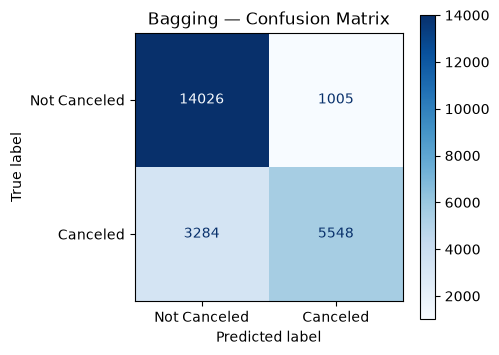

Bagging -> {'Accuracy': 0.8203, 'Precision': 0.8466, 'Recall': 0.6282, 'Weighted F1': 0.8133, 'ROC-AUC': 0.887}


In [26]:
fitted['Bagging'] = evaluate_model('Bagging',
    BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=10),
                      n_estimators=50, n_jobs=-1, random_state=RANDOM_STATE),
    X_train_p, y_train, X_test_p, y_test)

**Observation:** Bagging reaches an accuracy of 0.820 and ROC-AUC of 0.887, only slightly above the single Decision Tree it is built from (0.880), and clearly below Random Forest (0.912). Averaging 50 trees reduced variance a little, but the gain is small because every tree sees all the features and the trees end up quite similar. Precision is good (0.847), with 1,005 non-cancelled bookings wrongly flagged (about 7%). Recall is 0.628, almost the same as the Decision Tree: 3,284 of the 8,832 real cancellations (about 37%) were missed. Random Forest's random feature subsets make its trees less correlated, which is the likely reason it does better on both ROC-AUC and recall.

## MLP

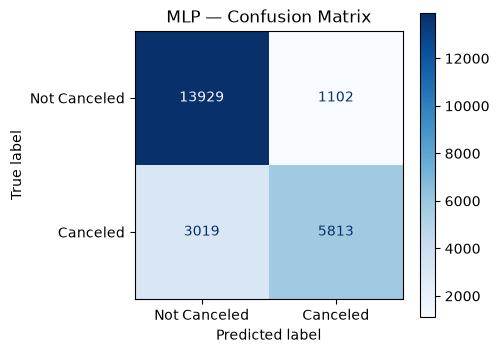

MLP -> {'Accuracy': 0.8273, 'Precision': 0.8406, 'Recall': 0.6582, 'Weighted F1': 0.822, 'ROC-AUC': 0.8952}


In [28]:
fitted['MLP'] = evaluate_model('MLP',
    MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', max_iter=200,
                  early_stopping=True, random_state=RANDOM_STATE),
    X_train_p, y_train, X_test_p, y_test)

**Observation:** The MLP reaches an accuracy of 0.827 and ROC-AUC of 0.895, the second-best result after Random Forest (0.912) and above the Decision Tree (0.880). It is the best of the non-forest models, which suggests a small neural network can pick up non-linear patterns across the scaled features. Precision is 0.841, with 1,102 non-cancelled bookings wrongly flagged (about 7%). Recall is 0.658: 3,019 of the 8,832 real cancellations (about 34%) were missed, which is better than the boosting and Bagging models but still below Random Forest (0.699). The MLP is harder to interpret than the tree models, since its weights don't map onto individual features, so Random Forest is the stronger choice when accuracy and explainability both matter.

AdaBoost: trees are trained one after another, and each new tree puts more weight on the examples the previous ones got wrong. learning_rate shrinks how much each tree contributes.
Gradient Boosting: each new tree is fit to the errors (residuals) of the ensemble so far, rather than to reweighted samples. learning_rate is the step size, so a smaller value usually needs more trees.
Bagging: many trees on bootstrap samples, with votes averaged. Unlike Random Forest, every tree sees all the features. It mainly reduces variance.
MLP: a small neural network with two hidden layers (64 and 32 neurons). It needs scaled inputs, which your preprocessor already provides. early_stopping holds out part of the training data and stops when the validation score stops improving, which protects against overfitting.

# The 10-algorithm comparison table

In [29]:
base_models = ['Logistic Regression', 'KNN', 'Decision Tree', 'Naive Bayes', 'SVM',
               'Random Forest', 'AdaBoost', 'Gradient Boosting', 'Bagging', 'MLP']

final_df = pd.DataFrame(results).T.loc[base_models].sort_values('ROC-AUC', ascending=False)
final_df.round(4)

,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
Random Forest,0.8419,0.8475,0.6985,0.8382,0.9120
MLP,0.8273,0.8406,0.6582,0.8220,0.8952
Bagging,0.8203,0.8466,0.6282,0.8133,0.8870
Gradient Boosting,0.8172,0.8509,0.6138,0.8094,0.8862
Decision Tree,0.8183,0.8413,0.6273,0.8113,0.8804
Logistic Regression,0.8108,0.8300,0.6147,0.8034,0.8615
SVM,0.7972,0.8971,0.5105,0.7807,0.8556
AdaBoost,0.8082,0.8706,0.5658,0.7967,0.8555
KNN,0.7582,0.6933,0.6218,0.7552,0.8056
Naive Bayes,0.7556,0.9456,0.3603,0.7196,0.7812


**Observation:** Random Forest is the best model, with a ROC-AUC of 0.912, accuracy of 0.842
and recall of 0.699. That is about 0.03 higher in ROC-AUC than the best Part A model (the
Decision Tree, 0.880). MLP (0.895), Bagging (0.887) and Gradient Boosting (0.886) also beat
the Decision Tree slightly, which fits the idea that averaging many trees reduces variance.
AdaBoost (0.856) did not improve on Part A, probably because its default weak learners are
one-split stumps. KNN (0.806) and Naive Bayes (0.781) are the weakest. Naive Bayes assumes
independent features, which does not hold here, and KNN was trained on an 8,000-row
subsample. Naive Bayes has the highest precision (0.946) but the lowest recall (0.360), so
it misses almost two thirds of cancellations. Since a missed cancellation costs the hotel an
empty room it could have resold, recall matters alongside accuracy, and Random Forest leads
on both.

# Hyperparameter tuning

## Random forest

{'max_depth': 20, 'n_estimators': 200} 0.9075


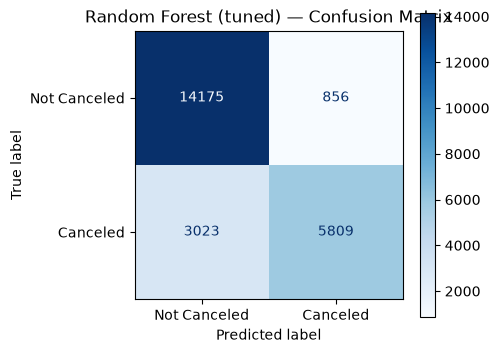

Random Forest (tuned) -> {'Accuracy': 0.8374, 'Precision': 0.8716, 'Recall': 0.6577, 'Weighted F1': 0.8315, 'ROC-AUC': 0.9084}


In [30]:
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={'n_estimators': [100, 200], 'max_depth': [10, 20]},
    cv=3, scoring='roc_auc', n_jobs=-1)
rf_grid.fit(X_train_p, y_train)
print(rf_grid.best_params_, round(rf_grid.best_score_, 4))

fitted['Random Forest (tuned)'] = evaluate_model('Random Forest (tuned)', rf_grid.best_estimator_,
    X_train_p, y_train, X_test_p, y_test)

**Observation:** GridSearchCV picked `max_depth=20` and `n_estimators=200`, with a cross-validated ROC-AUC of 0.9075. On the test set, the tuned Random Forest did not beat the default one overall: ROC-AUC went from 0.912 to 0.908, accuracy from 0.842 to 0.837, and recall from 0.699 to 0.658. Precision did improve, from 0.848 to 0.872, and false alarms fell from 1,110 to 856 (about 6% of non-cancelled bookings), but 3,023 real cancellations (about 34%) were missed, against 2,663 before. The likely reason is that the default forest has no depth limit (`max_depth=None`), and that option was not in the grid, so the search could only choose between 10 and 20. A depth-limited forest is more cautious, which explains the higher precision and lower recall. The improvement is therefore only in precision, and the default settings were already close to the best this model can do on this data.

## Gradient Boosting:

{'learning_rate': 0.2, 'max_depth': 5} 0.903


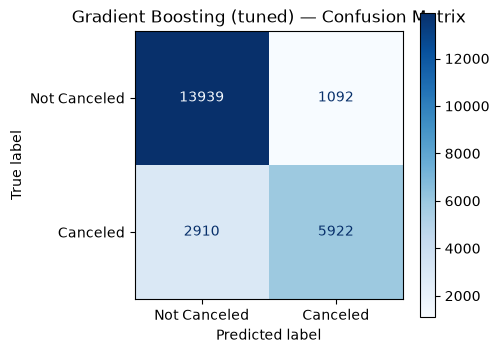

Gradient Boosting (tuned) -> {'Accuracy': 0.8323, 'Precision': 0.8443, 'Recall': 0.6705, 'Weighted F1': 0.8275, 'ROC-AUC': 0.9025}


In [31]:
gb_grid = GridSearchCV(
    GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE),
    param_grid={'learning_rate': [0.05, 0.1, 0.2], 'max_depth': [3, 5]},
    cv=3, scoring='roc_auc', n_jobs=-1)
gb_grid.fit(X_train_p, y_train)
print(gb_grid.best_params_, round(gb_grid.best_score_, 4))

fitted['Gradient Boosting (tuned)'] = evaluate_model('Gradient Boosting (tuned)', gb_grid.best_estimator_,
    X_train_p, y_train, X_test_p, y_test)

**Observation:** GridSearchCV picked `learning_rate=0.2` and `max_depth=5`, with a cross-validated ROC-AUC of 0.903. Tuning clearly helped Gradient Boosting on the test set: ROC-AUC rose from 0.886 to 0.903, accuracy from 0.817 to 0.832, weighted F1 from 0.809 to 0.828 and recall from 0.614 to 0.671. Precision fell slightly, from 0.851 to 0.844, and false alarms rose from 950 to 1,092 (about 7% of non-cancelled bookings), but missed cancellations dropped from 3,411 to 2,910 (about 33%). Deeper trees (`max_depth=5`) let the model capture feature interactions that the default depth of 3 could not, and the cross-validated score (0.903) agrees with the test score (0.9025), so the gain is not a lucky split. Both chosen values are at the edge of the grid, so larger values might do even better. Even so, the tuned model is still below the default Random Forest (ROC-AUC 0.912, recall 0.699).

## Before and after:

In [32]:
pd.DataFrame(results).T.loc[['Random Forest', 'Random Forest (tuned)',
                             'Gradient Boosting', 'Gradient Boosting (tuned)']].round(4)

,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
Random Forest,0.8419,0.8475,0.6985,0.8382,0.9120
Random Forest (tuned),0.8374,0.8716,0.6577,0.8315,0.9084
Gradient Boosting,0.8172,0.8509,0.6138,0.8094,0.8862
Gradient Boosting (tuned),0.8323,0.8443,0.6705,0.8275,0.9025


**Summary of tuning:** Tuning helped Gradient Boosting but not Random Forest.

- **Gradient Boosting:** ROC-AUC rose from 0.886 to 0.903 (+0.016), accuracy from 0.817 to 0.832, weighted F1 from 0.809 to 0.828, and recall from 0.614 to 0.671 (+0.057). Precision fell only slightly, from 0.851 to 0.844. Deeper trees (`max_depth=5`) and a larger `learning_rate` (0.2) clearly suited this data better than the defaults.
- **Random Forest:** ROC-AUC went from 0.912 to 0.908 and recall from 0.699 to 0.658, while precision rose from 0.848 to 0.872. The default forest was already close to the best this model can do, and the depth limit in the grid made it more cautious rather than better overall.

After tuning, Gradient Boosting closes most of the gap to Random Forest (ROC-AUC difference 0.026 before, 0.010 after), but the default Random Forest is still the best model on ROC-AUC, accuracy and recall.

# 5-fold cross-validation on the top two models

In [33]:
from sklearn.base import clone

fresh = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    'Naive Bayes': GaussianNB(),
    'SVM': SVC(kernel='linear', random_state=RANDOM_STATE, cache_size=1000),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE),
    'Bagging': BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=10), n_estimators=50,
                                 n_jobs=-1, random_state=RANDOM_STATE),
    'MLP': MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200,
                         random_state=RANDOM_STATE),
}

cv_rows = {}
for name in final_df.index[:2]:
    Xcv, ycv = (X_train_sub, y_train_sub) if name in ('KNN', 'SVM') else (X_train_p, y_train)
    scores = cross_val_score(clone(fresh[name]), Xcv, ycv, cv=5, scoring='roc_auc', n_jobs=-1)
    cv_rows[name] = {'Mean ROC-AUC': scores.mean(), 'Std': scores.std()}

pd.DataFrame(cv_rows).T.round(4)

,Mean ROC-AUC,Std
Random Forest,0.9121,0.0020
MLP,0.8927,0.0026


**Observation:** The cross-validated ROC-AUC is 0.9121 (std 0.0020) for Random Forest and 0.8927 (std 0.0026) for the MLP. Both are very close to their test-set scores (0.912 and 0.895), so the test results were not a lucky split. The standard deviations are small, so both models perform consistently across different slices of the data. Random Forest is higher than the MLP by about 0.02, and that gap is much larger than the fold-to-fold variation, so the ranking is reliable.

In [36]:
final_name = 'Random Forest'
final_model = fitted[final_name]
print(final_name, {k: round(v, 4) for k, v in results[final_name].items()})

joblib.dump(final_model, '../models/best_classifier.pkl')
joblib.dump(preprocessor, '../models/preprocessor.pkl')

Random Forest {'Accuracy': 0.8419, 'Precision': 0.8475, 'Recall': 0.6985, 'Weighted F1': 0.8382, 'ROC-AUC': 0.912}


['../models/preprocessor.pkl']

# Comparision Table

The five Part-B algorithms are compared using the same evaluation metrics
used for Part A.

The models are ranked according to ROC-AUC to compare their ability to
distinguish canceled and non-canceled bookings across different thresholds.

In [39]:
part_b_models = [
    'Random Forest',
    'AdaBoost',
    'Gradient Boosting',
    'Bagging',
    'MLP'
]

part_b_comparison = (
    pd.DataFrame(results)
    .T
    .loc[part_b_models]
    .sort_values('ROC-AUC', ascending=False)
)

part_b_comparison.round(4)

,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
Random Forest,0.8419,0.8475,0.6985,0.8382,0.9120
MLP,0.8273,0.8406,0.6582,0.8220,0.8952
Bagging,0.8203,0.8466,0.6282,0.8133,0.8870
Gradient Boosting,0.8172,0.8509,0.6138,0.8094,0.8862
AdaBoost,0.8082,0.8706,0.5658,0.7967,0.8555


##  Final Comparison — All 10 Classification Algorithms

The final classification comparison combines Part A and Part B.

All ten algorithms are evaluated using:

- Accuracy
- Precision
- Recall
- Weighted F1-score
- ROC-AUC

The models use the same held-out test set for evaluation.

In [40]:
final_comparison = (
    pd.DataFrame(results)
    .T
    .sort_values('ROC-AUC', ascending=False)
)

final_comparison.round(4)

,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
Random Forest,0.8419,0.8475,0.6985,0.8382,0.9120
Random Forest (tuned),0.8374,0.8716,0.6577,0.8315,0.9084
Gradient Boosting (tuned),0.8323,0.8443,0.6705,0.8275,0.9025
MLP,0.8273,0.8406,0.6582,0.8220,0.8952
Bagging,0.8203,0.8466,0.6282,0.8133,0.8870
Gradient Boosting,0.8172,0.8509,0.6138,0.8094,0.8862
Decision Tree,0.8183,0.8413,0.6273,0.8113,0.8804
Logistic Regression,0.8108,0.8300,0.6147,0.8034,0.8615
SVM,0.7972,0.8971,0.5105,0.7807,0.8556
AdaBoost,0.8082,0.8706,0.5658,0.7967,0.8555


## Final Model Selection

**Selected model:** Random Forest (default settings: 200 trees, no depth limit)

**Metric priority:** I selected the model mainly on ROC-AUC and recall. The classes are imbalanced (about 63% not cancelled, 37% cancelled), so accuracy alone can hide a model that misses many cancellations, and a missed cancellation costs the hotel an empty room it could have resold.

**Performance:** On the test set it reaches ROC-AUC 0.912, accuracy 0.842, precision 0.848, recall 0.699 and weighted F1 0.838. It is the best model on ROC-AUC, accuracy, F1 and recall among all 10 base models and the tuned versions. 5-fold cross-validation gave 0.9121 ± 0.0020, which agrees with the test score.

**Effect of tuning:** Tuning did not improve the Random Forest (ROC-AUC 0.912 to 0.908, recall 0.699 to 0.658, with precision rising from 0.848 to 0.872), so the default model is kept. Tuning helped Gradient Boosting much more (ROC-AUC 0.886 to 0.903, recall 0.614 to 0.671), but it still stays below Random Forest.

**Trade-offs:** Random Forest trains its trees in parallel, so it is faster than Gradient Boosting, which builds trees one after another. It is harder to interpret than Logistic Regression or a single tree, but feature importance gives a rough picture (lead time, ADR and deposit type matter most). Averaging many trees keeps its overfitting risk low, and the close match between its CV and test scores supports that. Its main weakness is recall: it still misses about 30% of real cancellations.

**Conclusion:** A hotel could use this model to flag high-risk bookings early, for example by asking for a deposit or sending a reminder. A limitation is that it was trained on one historical dataset, so its performance on other hotels or later periods is untested.